<a href="https://colab.research.google.com/github/erikarosado/ia-y-aprendizaje-automatico/blob/main/MNA_IAyAA_Actividad_semana_8_Sistema_Recomendacion_con_Agente_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Maestría en Inteligencia Artificial Aplicada**
### **Curso: Inteligencia Artificial y Aprendizaje Automático**
#### Tecnológico de Monterrey
#### Prof Luis Eduardo Falcón Morales

### **Actividad de la Semana: Sistemas de Recomendación basados en factorización SVD y Agentes**


**Esta Actividad deberá resolverse de manera individual.**

* **Nombre:** Erika Rosado Treviño

* **Matrícula:** A00846135


**Incluye todas las librerías y líneas de código que consideres adecuadas.**

In [2]:
import os, re, json, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

np.random.seed(42)
pd.set_option("display.max_colwidth", 70)


# **Ejercicio - 1: cargando datos**

In [3]:
DATA_DIR = "ml-1m"
if not os.path.exists(os.path.join(DATA_DIR, "ratings.dat")):
    urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-1m.zip", "ml-1m.zip")
    with zipfile.ZipFile("ml-1m.zip") as z:
        z.extractall(".")

kw = dict(sep="::", engine="python", encoding="latin-1")
ratings = pd.read_csv(f"{DATA_DIR}/ratings.dat", names=["user_id", "movie_id", "rating", "timestamp"], **kw)
movies  = pd.read_csv(f"{DATA_DIR}/movies.dat",  names=["movie_id", "title", "genres"], **kw)
users   = pd.read_csv(f"{DATA_DIR}/users.dat",   names=["user_id", "gender", "age", "occupation", "zip"], **kw)

print("Usuarios (users.dat)            :", users.user_id.nunique())
print("Usuarios que evalúan            :", ratings.user_id.nunique())
print("Películas (catálogo movies.dat) :", movies.movie_id.nunique())
print("Películas con al menos 1 rating :", ratings.movie_id.nunique())
print("Evaluaciones                    :", len(ratings))
print("Escala de evaluación            :", sorted(ratings.rating.unique()))
print("Rating mínimo / máximo / media  :", ratings.rating.min(), ratings.rating.max(), round(ratings.rating.mean(), 3))
ratings.head()


Usuarios (users.dat)            : 6040
Usuarios que evalúan            : 6040
Películas (catálogo movies.dat) : 3883
Películas con al menos 1 rating : 3706
Evaluaciones                    : 1000209
Escala de evaluación            : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Rating mínimo / máximo / media  : 1 5 3.582


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291



a) 6,040 usuarios, 3,883 películas en el catálogo (3,706 con al menos una evaluación) y 1,000,209 evaluaciones.

b) Escala entera de 1 a 5 estrellas (1, 2, 3, 4, 5; no hay medias estrellas).


# **Ejercicio - 2: matriz de utilidad**

In [4]:
user_ids  = np.sort(ratings.user_id.unique())
movie_ids = np.sort(ratings.movie_id.unique())
u_idx = {u: i for i, u in enumerate(user_ids)}
m_idx = {m: i for i, m in enumerate(movie_ids)}
ratings["u"] = ratings.user_id.map(u_idx)
ratings["m"] = ratings.movie_id.map(m_idx)
n_u, n_m = len(user_ids), len(movie_ids)

# Matriz de utilidad usuarios x películas (dispersa; 0 = sin evaluar)
R = csr_matrix((ratings.rating.values.astype(np.float32), (ratings.u.values, ratings.m.values)), shape=(n_u, n_m))

# Metadatos de películas alineados con las columnas de R
movies_r = movies.set_index("movie_id").loc[movie_ids].reset_index()

density  = R.nnz / (n_u * n_m)
print("Dimensión de la matriz:", R.shape)
print("Entradas observadas   :", R.nnz)
print(f"Densidad              : {density:.4%}")
print(f"Dispersión (sparsity) : {1 - density:.4%}")


Dimensión de la matriz: (6040, 3706)
Entradas observadas   : 1000209
Densidad              : 4.4684%
Dispersión (sparsity) : 95.5316%


a) Matriz de 6,040 × 3,706, con ≈ 22.4 millones de celdas de las cuales solo 1,000,209 están observadas: densidad ≈ 4.47 %, dispersión ≈ 95.53 %.

b) Más del 95 % de los pares (usuario, película) no tienen calificación: cada usuario ha visto una fracción minúscula del catálogo. La información es escasa, hay mucha incertidumbre por usuario y el problema de *cold start* es real. Además, la ausencia de rating no significa "no le gusta", sino "no la ha visto o no la ha calificado".

c)Usar formatos dispersos (CSR/CSC) para guardar solo las 1M entradas observadas y no 22M de celdas (≈ 90 MB en denso float32 vs. pocos MB en disperso).
Usar algoritmos que aprovechen la dispersión (`svds`, `TruncatedSVD`, ALS/SGD) y evitar densificar la matriz salvo cuando sea necesario.
Definir qué hacer con los faltantes: rellenar con 0 distorsiona la factorización; por eso aquí centramos por usuario solo las entradas observadas (los faltantes quedan en 0 = "promedio del usuario").
La evaluación debe hacerse solo sobre entradas observadas y el riesgo de sobreajuste es alto con muchos factores.
El SVD clásico no está definido con valores faltantes; lo que se obtiene es una aproximación que trata los faltantes como cero.


# **Ejercicio - 3: varianza explicada y número de componentes latentes**

Componentes para 80% de varianza acumulada: 709
Componentes para 90% de varianza acumulada: 1082
Componentes para 95% de varianza acumulada: 1440


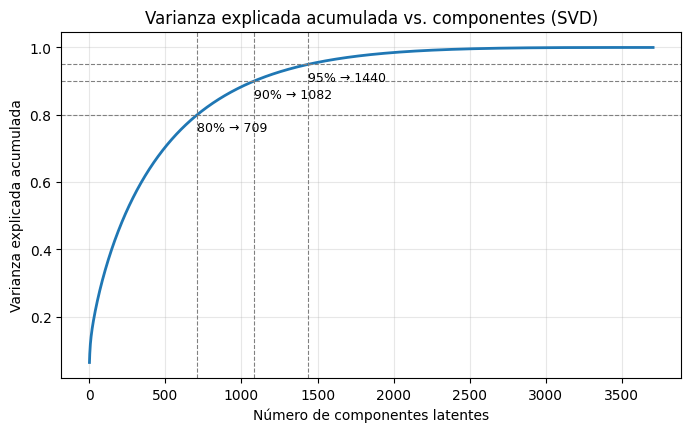

In [6]:
def center_by_user(M):
    "Resta a cada rating observado el promedio del usuario (los faltantes quedan en 0)."
    M = M.tocsr().astype(np.float32)
    cnt = np.diff(M.indptr)
    sums = np.asarray(M.sum(axis=1)).ravel()
    mu = np.zeros(M.shape[0], dtype=np.float32)
    np.divide(sums, cnt, out=mu, where=cnt > 0)
    mu[cnt == 0] = mu[cnt > 0].mean()
    Mc = M.copy()
    Mc.data = Mc.data - np.repeat(mu, cnt)
    return Mc, mu

R_c, mu_users = center_by_user(R)

# Valores singulares completos (matriz 6040x3706
s_all = np.linalg.svd(R_c.toarray(), compute_uv=False)
exp_var_ratio = s_all**2 / np.sum(s_all**2)      # varianza (energía) explicada por componente
cum_var = np.cumsum(exp_var_ratio)

n80, n90, n95 = [int(np.searchsorted(cum_var, p) + 1) for p in (0.80, 0.90, 0.95)]
print(f"Componentes para 80% de varianza acumulada: {n80}")
print(f"Componentes para 90% de varianza acumulada: {n90}")
print(f"Componentes para 95% de varianza acumulada: {n95}")

plt.figure(figsize=(8, 4.5))
plt.plot(np.arange(1, len(cum_var) + 1), cum_var, lw=2)
for p, n in [(0.8, n80), (0.9, n90), (0.95, n95)]:
    plt.axhline(p, ls="--", c="gray", lw=0.8); plt.axvline(n, ls="--", c="gray", lw=0.8)
    plt.text(n, p - 0.05, f"{int(p*100)}% → {n}", fontsize=9)
plt.xlabel("Número de componentes latentes"); plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada vs. componentes (SVD)"); plt.grid(alpha=.3); plt.show()


b) Los números para 80 %, 90 % y 95 % se imprimen arriba. Como la matriz de ratings es dispersa y ruidosa, la varianza se reparte en muchos componentes (la curva sube lentamente, sin codo marcado), por lo que alcanzar 90 % o 95 % exige cientos o miles de factores.

c) Solo con el criterio de varianza, un valor razonable es el del 80 % (`n80`), pues 90 % y 95 % añaden mucha complejidad para capturar sobre todo ruido y ajuste a los datos de entrenamiento. Sin embargo, la varianza explicada *o mide capacidad predictiva (se calcula con los datos con los que se entrena), así que este valor se contrasta con RMSE en el Ejercicio 4 y se decide en el Ejercicio 5.


# **Ejercicio - 4: métrica RMSE y número de componentes latentes**


RMSE línea base (promedio del usuario): 1.0394
  k  RMSE_test
  2     0.9894
  5     0.9778
 10     0.9685
 20     0.9633
 30     0.9642
 40     0.9661
 50     0.9682
 75     0.9742
100     0.9796
150     0.9891
200     0.9969


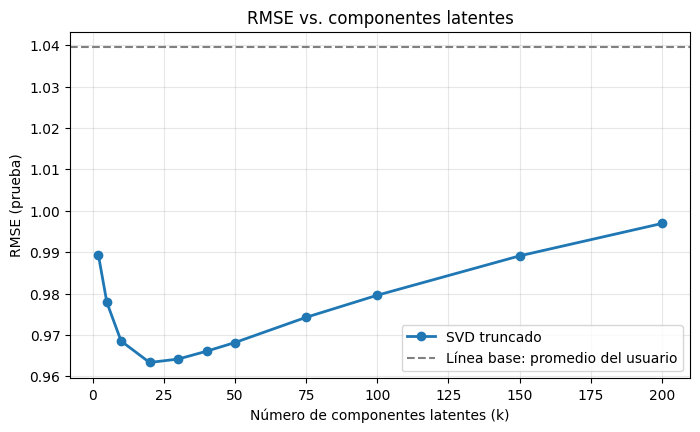

k con RMSE mínimo: 20 | k más pequeño con RMSE a <=0.5% del mínimo: 20


In [7]:
# a) 80% entrenamiento / 20% prueba sobre las evaluaciones
train_df, test_df = train_test_split(ratings, test_size=0.20, random_state=42)
R_train = csr_matrix((train_df.rating.values.astype(np.float32), (train_df.u.values, train_df.m.values)), shape=(n_u, n_m))
R_train_c, mu_train = center_by_user(R_train)
t_u, t_i, t_r = test_df.u.values, test_df.m.values, test_df.rating.values

# b) SVD truncado entrenado solo con train (una descomposición con k_max; se reutiliza para cada k)
k_max = 200
U, S, Vt = svds(R_train_c, k=k_max, random_state=42)
order = np.argsort(-S); U, S, Vt = U[:, order], S[order], Vt[order, :]

def rmse_k(k):
    pred = mu_train[t_u] + np.sum((U[t_u, :k] * S[:k]) * Vt[:k, t_i].T, axis=1)
    pred = np.clip(pred, 1, 5)
    return np.sqrt(np.mean((pred - t_r) ** 2))

ks = [2, 5, 10, 20, 30, 40, 50, 75, 100, 150, 200]
rmses = [rmse_k(k) for k in ks]
baseline = np.sqrt(np.mean((np.clip(mu_train[t_u], 1, 5) - t_r) ** 2))
print(f"RMSE línea base (promedio del usuario): {baseline:.4f}")
print(pd.DataFrame({"k": ks, "RMSE_test": np.round(rmses, 4)}).to_string(index=False))

# c) Gráfica RMSE vs k
plt.figure(figsize=(8, 4.5))
plt.plot(ks, rmses, "o-", lw=2, label="SVD truncado")
plt.axhline(baseline, ls="--", c="gray", label="Línea base: promedio del usuario")
plt.xlabel("Número de componentes latentes (k)"); plt.ylabel("RMSE (prueba)")
plt.title("RMSE vs. componentes latentes"); plt.grid(alpha=.3); plt.legend(); plt.show()

# d) Selección: k de menor RMSE y el k más pequeño dentro del 0.5% del mínimo
k_rmse_min = ks[int(np.argmin(rmses))]
k_rmse_par = next(k for k, r in zip(ks, rmses) if r <= min(rmses) * 1.005)
print(f"k con RMSE mínimo: {k_rmse_min} | k más pequeño con RMSE a <=0.5% del mínimo: {k_rmse_par}")


Se elige el k con menor RMSE en prueba, o bien el k más pequeño cuyo RMSE está a menos de 0.5 % del mínimo (criterio de parsimonia: menor costo, menos sobreajuste y prácticamente el mismo error). Al aumentar k el RMSE baja al capturar más estructura y, pasado cierto punto, se estanca o vuelve a subir porque el modelo empieza a ajustar ruido de los usuarios de entrenamiento. Los valores concretos se imprimen arriba. Todos deben quedar por debajo de la línea base.


# **Ejercicio - 5: comparación varianza explicada vs RMSE**

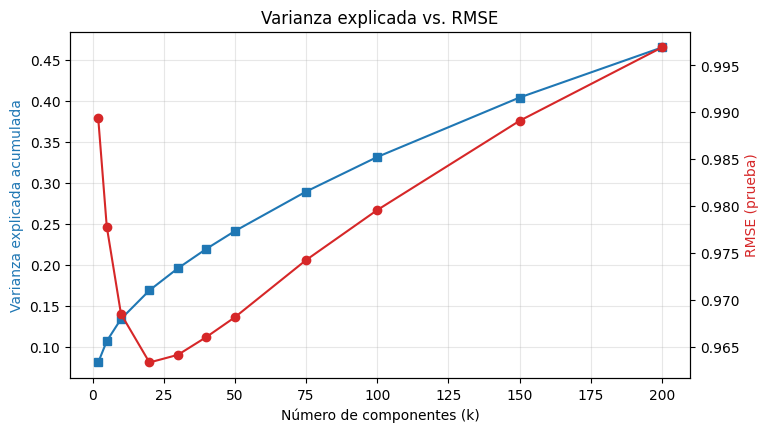

  k  Var. acumulada   RMSE
  2          0.0805 0.9894
  5          0.1066 0.9778
 10          0.1337 0.9685
 20          0.1687 0.9633
 30          0.1957 0.9642
 40          0.2194 0.9661
 50          0.2411 0.9682
 75          0.2894 0.9742
100          0.3317 0.9796
150          0.4044 0.9891
200          0.4656 0.9969

Número de componentes seleccionado: K = 20 (varianza acumulada 16.87%, RMSE 0.9633; criterio varianza sugería n80 = 709)


In [10]:
var_at_k = [cum_var[k - 1] for k in ks]
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(ks, var_at_k, "s-", c="tab:blue"); ax1.set_xlabel("Número de componentes (k)")
ax1.set_ylabel("Varianza explicada acumulada", color="tab:blue")
ax2 = ax1.twinx(); ax2.plot(ks, rmses, "o-", c="tab:red"); ax2.set_ylabel("RMSE (prueba)", color="tab:red")
plt.title("Varianza explicada vs. RMSE"); ax1.grid(alpha=.3); plt.show()

print(pd.DataFrame({"k": ks, "Var. acumulada": np.round(var_at_k, 4), "RMSE": np.round(rmses, 4)}).to_string(index=False))

K = k_rmse_par
print(f"\nNúmero de componentes seleccionado: K = {K} "
      f"(varianza acumulada {cum_var[K-1]:.2%}, RMSE {rmses[ks.index(K)]:.4f}; criterio varianza sugería n80 = {n80})")


Los dos criterios responden preguntas distintas: la varianza explicada mide cuánto de la matriz de entrenamiento se reconstruye (siempre crece con k), mientras que el RMSE mide el error sobre datos no vistos. Por ello se prioriza el RMSE: se toma el menor k con RMSE prácticamente igual al mínimo (`K`, impreso arriba). Este K explica una fracción de varianza menor que el 80-90 %, lo cual es esperable: cuando hay mucho ruido y faltantes, retener más varianza no mejora las recomendaciones. Usaremos este `K` en lo que sigue.


# **Ejercicio - 6: sistema de recomendación colaborativo**

In [11]:
# SVD truncado con K componentes sobre TODA la matriz de utilidad
U_f, S_f, Vt_f = svds(R_c, k=K, random_state=42)
o = np.argsort(-S_f); U_f, S_f, Vt_f = U_f[:, o], S_f[o], Vt_f[o, :]
item_factors = Vt_f.T * S_f            # (n_películas x K): factores latentes de cada película

# a) Matriz de similitud del coseno entre películas
sim_svd = cosine_similarity(item_factors)
# b) Dimensión
print("Dimensión de la matriz de similitud:", sim_svd.shape)

def find_idx(query):
    exact = movies_r.index[movies_r.title == query]
    if len(exact): return int(exact[0])
    mask = movies_r.title.str.contains(query, case=False, regex=False)
    if not mask.any(): raise ValueError(f"No se encontró '{query}' en movies.dat")
    return int(np.flatnonzero(mask.values)[0])

def recommend(query, sim, n=10):
    i = find_idx(query)
    s = sim[i].copy(); s[i] = -np.inf
    top = np.argsort(-s)[:n]
    return pd.DataFrame({"title": movies_r.title.values[top], "genres": movies_r.genres.values[top],
                         "similarity": np.round(sim[i, top], 4)})

# c) Película de preferencia y sus 10 recomendaciones
FAVORITE = "Toy Story (1995)"
svd_rec = recommend(FAVORITE, sim_svd, 10)
print(f"\nRecomendaciones SVD para: {FAVORITE}")
print(svd_rec.to_string(index=False))


Dimensión de la matriz de similitud: (3706, 3706)

Recomendaciones SVD para: Toy Story (1995)
                                      title                              genres  similarity
                         Toy Story 2 (1999)         Animation|Children's|Comedy      0.9481
                       Bug's Life, A (1998)         Animation|Children's|Comedy      0.8857
                             Aladdin (1992) Animation|Children's|Comedy|Musical      0.8300
                                Babe (1995)             Children's|Comedy|Drama      0.8138
                     Iron Giant, The (1999)                Animation|Children's      0.7986
                Beauty and the Beast (1991)        Animation|Children's|Musical      0.7933
                      Lion King, The (1994)        Animation|Children's|Musical      0.7477
                         Chicken Run (2000)         Animation|Children's|Comedy      0.7362
Winnie the Pooh and the Blustery Day (1968)                Animation|Children'

b) La matriz de similitud es de 3,706 × 3,706 (películas × películas), simétrica y con 1 en la diagonal.

d) Sí son coherentes. Toy Story 2 queda primero con 0.9481, algo esperado por ser la secuela directa, del mismo estudio y con el mismo público.
Las posiciones 2 a 10 son películas de animación y cine familiar. Nueve de las diez comparten los géneros Animation y Children’s con Toy Story. La única excepción es Babe, que es Children’s, Comedy y Drama.
Aparecen clásicos de Disney (Aladdin, La Bella y la Bestia, El Rey León, Fantasia 2000) y otras películas de la época (A Bug’s Life, Chicken Run, The Iron Giant).
Las similitudes bajan de forma gradual, de 0.95 a 0.71, lo que da un ranking razonable.


e) Podría decirse que cada persona tiene ciertos gustos que no comparte publicamente, por ejemplo que le gustan tanto las películas infantiles, como de acción o de terror, y que cada película tiene un “perfil” en esos mismos ejes. SVD descubre esos ejes por sí solo, observando solo quién calificó qué y con cuántas estrellas, sin que nadie le diga los géneros.
Después resume cada película con unos pocos números (su perfil). Dos películas se consideran parecidas si les gustan, o les disgustan, a las mismas personas. En el caso de Toy Story, a quienes les gustó también les gustaron Toy Story 2, Aladdin o El Rey León, así que sus perfiles quedan muy cerca. Recomendar es buscar las películas con el perfil más cercano a la que ya te gustó.



# **Ejercicio - 7: sistema de recomendación híbrido**

In [12]:
# a) Año de lanzamiento -> década
movies_r["year"] = movies_r.title.str.extract(r"\((\d{4})\)\s*$")[0].astype(int)
movies_r["decade"] = (movies_r.year // 10) * 10
decade_oh = pd.get_dummies(movies_r.decade, prefix="dec").astype(np.float32)

# b) Género de la película (multi-hot) y factores de users.dat agregados por película:
#    proporción de mujeres, distribución por grupo de edad y distribución por ocupación de quienes la calificaron
genre_oh = movies_r.genres.str.get_dummies(sep="|").astype(np.float32)

ru = ratings[["user_id", "movie_id"]].merge(users, on="user_id")
ru["female"] = (ru.gender == "F").astype(float)
gender_f = ru.groupby("movie_id").female.mean().reindex(movie_ids).fillna(ru.female.mean()).to_frame("pct_female")
age_f    = pd.crosstab(ru.movie_id, ru.age, normalize="index").reindex(movie_ids).fillna(0)
occ_f    = pd.crosstab(ru.movie_id, ru.occupation, normalize="index").reindex(movie_ids).fillna(0)

def block(X, w, zscore=False, rownorm=True):
    X = np.asarray(X, dtype=np.float32)
    if zscore:
        X = (X - X.mean(0)) / (X.std(0) + 1e-8)     # evita que domine el perfil "promedio" de la población
    if rownorm:
        X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
    return X * w

weights = dict(latent=1.0, decade=0.5, genre=0.5, gender=0.3, age=0.3, occupation=0.3)
H = np.hstack([
    block(item_factors, weights["latent"]),                       # factores latentes SVD (norma 1)
    block(decade_oh,    weights["decade"]),
    block(genre_oh,     weights["genre"]),
    block(gender_f,     weights["gender"], zscore=True, rownorm=False),
    block(age_f,        weights["age"],    zscore=True),
    block(occ_f,        weights["occupation"], zscore=True),
])
print("Dimensión de la matriz híbrida:", H.shape,
      f"= {K} latentes + {decade_oh.shape[1]} décadas + {genre_oh.shape[1]} géneros + 1 género de usuarios + {age_f.shape[1]} edad + {occ_f.shape[1]} ocupación")

sim_hyb = cosine_similarity(H)

# e) Comparación para la misma película
hyb_rec = recommend(FAVORITE, sim_hyb, 10)
comparison = pd.DataFrame({
    "Rank": range(1, 11),
    "SVD": svd_rec.title.values, "Sim SVD": svd_rec.similarity.values,
    "Híbrido": hyb_rec.title.values, "Sim Híbrido": hyb_rec.similarity.values})
print(f"\nComparación para: {FAVORITE}")
print(comparison.to_string(index=False))
print("\nPelículas en común en ambos top-10:", len(set(svd_rec.title) & set(hyb_rec.title)))


Dimensión de la matriz híbrida: (3706, 77) = 20 latentes + 10 décadas + 18 géneros + 1 género de usuarios + 7 edad + 21 ocupación

Comparación para: Toy Story (1995)
 Rank                                         SVD  Sim SVD                     Híbrido  Sim Híbrido
    1                          Toy Story 2 (1999)   0.9481          Toy Story 2 (1999)       0.9613
    2                        Bug's Life, A (1998)   0.8857        Bug's Life, A (1998)       0.9281
    3                              Aladdin (1992)   0.8300              Aladdin (1992)       0.8679
    4                                 Babe (1995)   0.8138      Iron Giant, The (1999)       0.8335
    5                      Iron Giant, The (1999)   0.7986 Beauty and the Beast (1991)       0.8147
    6                 Beauty and the Beast (1991)   0.7933                 Babe (1995)       0.8091
    7                       Lion King, The (1994)   0.7477       Lion King, The (1994)       0.7889
    8                          Chi

a y b) Factores seleccionados y transformaciones:
* Década (a partir del año extraído del título, one-hot): captura la época, que influye en estilo y público y es mejor que el año exacto porque agrupa.
* Género (multi-hot, 18 géneros): aporta contenido explícito que SVD solo capta de forma indirecta.
* De `users.dat`, como los datos son de usuarios y no de películas, se agregan por película los perfiles de quienes la calificaron: proporción de mujeres, distribución por grupo de edad (7 grupos) y distribución por ocupación (21). Se estandarizan (z-score) para que cuente lo que distingue a una película de otra y no el perfil promedio de la población.
* Cada bloque se normaliza (norma 1) y se multiplica por un peso (latente 1.0, década y género 0.5, usuarios 0.3) para que ningún bloque domine el coseno.

c) La dimensión se imprime arriba: 3,706 filas × (K + 10 + 18 + 1 + 7 + 21) columnas.

d) Beneficios: (1) reduce el problema del cold start de ítems: una película nueva o con pocas evaluaciones tiene factores latentes ruidosos, pero sí tiene década y género; (2) recomendaciones más coherentes y explicables (se puede decir "comparten género y década"); (3) permite controlar con pesos el balance entre comportamiento colectivo y contenido; (4) mayor robustez ante la dispersión del 95 %. A cambio: más hiperparámetros (pesos) que ajustar y riesgo de que el contenido sobrepese al comportamiento.

f) Comentarios: Para Toy Story, ambos métodos dan resultados muy parecidos: coinciden 7 de las 10 películas y los tres primeros lugares son idénticos (Toy Story 2, A Bug’s Life y Aladdin), lo que indica que el híbrido conserva lo que SVD ya encontraba. La diferencia principal está en la época: salen Chicken Run, Winnie the Pooh y Fantasia 2000, de 1968 y 2000, y entran The Wrong Trousers, A Grand Day Out y Mulan, todas de los años 90 como Toy Story, efecto atribuible al bloque de décadas. Las similitudes del híbrido son más altas porque los bloques de contenido añaden coincidencias, aunque no son directamente comparables con las de SVD al calcularse en espacios distintos.
En conclusión, para una película popular como Toy Story, donde SVD ya cuenta con muchos datos, ambos métodos son coherentes y la ventaja del híbrido es sobre todo de homogeneidad de época y explicabilidad, no de calidad. Su valor real aparecería con películas poco calificadas o nuevas, caso que este ejemplo no prueba, y los resultados dependen de los pesos elegidos para cada bloque.



# **Ejercicio - 10: Reporte ejecutivo**

**Para:** CEO  **De:** Equipo de Ciencia de Datos  **Asunto:** Recomendación de método para producción

**Resumen.** Evaluamos tres enfoques de recomendación de películas con MovieLens 1M (6,040 usuarios, 3,706 películas, ≈1M evaluaciones, 95.5 % de la matriz vacía): (1) filtrado colaborativo con SVD truncado, (2) un modelo híbrido que añade género, década y perfil de audiencia y (3) un agente basado en LLM (`claude-sonnet-4-6`) que selecciona y explica las recomendaciones.

**Hallazgos.**
* El número de componentes se eligió por error de predicción (RMSE) sobre datos no vistos y no por varianza explicada, porque la varianza crece siempre con más factores y no garantiza mejores recomendaciones.
* El SVD es barato y escalable, pero es una "caja negra" y falla con películas nuevas o poco calificadas.
* El híbrido resuelve parte de ese problema con información de contenido, mantiene el costo bajo y permite explicar la recomendación.
* El agente LLM mejora la experiencia (explicaciones personalizadas), pero cuesta más por solicitud, añade latencia, dependencia de un proveedor y riesgo de alucinaciones.

**Recomendación.** Poner en producción una **arquitectura por capas**: el **sistema híbrido como motor de recomendación** (rápido, barato, auditable) y, **opcionalmente, el agente LLM solo como capa de explicación** sobre las candidatas del híbrido, restringido a esa lista, con validación automática de la salida y activado de forma gradual (A/B test) en segmentos donde la explicación aporte valor. Así se obtiene calidad y explicabilidad sin comprometer costos ni confiabilidad.

**Riesgos y siguientes pasos.** (1) Validar con métricas de ranking (precision@k, NDCG) y pruebas A/B con usuarios reales, ya que RMSE no mide la calidad del top-N. (2) Los datos son de 2003: hay que reentrenar con datos actuales. (3) Monitorear costo/latencia del LLM y establecer *fallback* al híbrido si el LLM falla. (4) Atender sesgo de popularidad y privacidad de los datos demográficos.


# **Ejercicio - 11: comentarios finales**

* La actividad permitió ver cómo evoluciona un sistema de recomendación: de un modelo puramente colaborativo (SVD) a uno híbrido y finalmente a un agente que explica en lenguaje natural.
* Aprendí que **elegir los componentes latentes por varianza explicada no basta**: se debe validar con una métrica predictiva (RMSE) sobre datos de prueba y considerar parsimonia.
* El trabajo con matrices dispersas obliga a pensar en eficiencia (formatos CSR, `svds`) y en cómo tratar los faltantes (centrado por usuario).
* El enfoque híbrido mostró el valor de combinar comportamiento y contenido, y la importancia de normalizar y ponderar los bloques de variables.
* El agente LLM añade valor en explicabilidad y experiencia, pero hay que acotarlo (candidatas, JSON, temperatura 0) y verificar sus salidas para controlar alucinaciones.
* Limitaciones: datos de 2003, una sola partición train/test, RMSE como única métrica y evaluación del agente basada en pocos perfiles. Como trabajo futuro: métricas de ranking, validación cruzada, ajuste de los pesos del híbrido y pruebas con usuarios reales.


# **++++ Fin de la Actividad de la semana: Sistemas de Recomendación +++**